# Campaign Incrementality & Customer Uplift Modeling
## An end-to-end analysis of the Hillstrom randomized email experiment

**Business decision:** Should the retailer send either campaign, and can an estimated-uplift ranking allocate a limited mailing budget better than a purchase-propensity list?

This notebook performs the analysis from the raw data: validation, exploratory plots, randomization diagnostics, causal contrasts, interaction tests, power planning, preprocessing, three model fits, and out-of-sample policy evaluation. It does **not** load precomputed model scores or effect tables.

### Contents
1. Reproducibility and data validation
2. Customer profiles and campaign outcomes
3. Randomization checks and average treatment effects
4. Exploratory heterogeneity and future experiment power
5. Leakage-safe preparation and explicit ML training
6. Holdout response diagnostics, deciles, Qini and targeting policies
7. Scenario economics, interpretation and recommendations

### Scope and limitations
- 64,000 customers were randomized to Mens E-Mail, Womens E-Mail or No E-Mail. Outcomes cover two weeks.
- `mens` and `womens` describe **prior purchases**, not customer gender; `newbie` is the supplied new-customer flag. No loyalty tiers are invented.
- Conversion is the primary analysis outcome; visit and spend are secondary, as specified in the project brief. This is **not** a claim that the original 2008 experiment or this retrospective notebook was prospectively registered.
- The Mens-versus-control ML comparison and its split are frozen in configuration. This rerun reproduces an already-inspected holdout; it does not create fresh external validation.
- Randomization supports average effects. An individual's treatment effect is never observed.
- Costs and margins are assumptions, not supplied measurements. BigQuery SQL has not been executed against a live project; this notebook runs locally in Python.

## 1. Reproducibility and data validation

From the repository root, create/activate a Python environment and run:
```bash
python -m pip install -e ".[notebook,tracking]"
python scripts/ingest_data.py
```
Open this notebook in a kernel belonging to that environment and run **all cells in order**. The bootstrap uses the configured 10,000 draws for whole-arm effects and 2,000 for targeting differences. The notebook records execution outputs but does not overwrite the pipeline's evidence CSVs.

In [1]:
from pathlib import Path
import hashlib
import platform
import sys
from importlib.metadata import version

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'configs' / 'experiment.yaml').is_file()
            and (p / 'src' / 'campaign_ml').is_dir())
sys.path.insert(0, str(root / 'src'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy import stats
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             brier_score_loss, log_loss, roc_curve,
                             precision_recall_curve)
from sklearn.calibration import calibration_curve

from campaign_ml.config import load_config
from campaign_ml.ingestion import sha256_of
from campaign_ml.validation import load_raw, prepare_clean_table, run_all_checks, FEATURE_COLUMNS
from campaign_ml import experimentation as ex
from campaign_ml import evaluation as ev
from campaign_ml import power as pw
from campaign_ml.features import make_splits, build_features, assert_no_leakage
from campaign_ml.uplift import PropensityModel, SLearner, TLearner, lightgbm_params, feature_importance

config = load_config(root / 'configs' / 'experiment.yaml')
experiment = config['experiment']
modelling = config['modelling']
alpha = float(experiment['alpha'])
seed = int(modelling['split']['seed'])
bootstrap_cfg = experiment['bootstrap']
comparison = next(c for c in experiment['comparisons']
                  if c['name'] == modelling['primary_comparison'])
arm_order = [experiment['arms'][k] for k in ['control', 'mens', 'womens']]
colors = ['#6b7280', '#2563eb', '#db2777']
plt.rcParams.update({'figure.figsize': (10, 4.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 24)
display(pd.DataFrame({'package': ['python', 'numpy', 'pandas', 'scikit-learn', 'lightgbm'],
                      'version': [platform.python_version(), version('numpy'), version('pandas'),
                                  version('scikit-learn'), version('lightgbm')]}))

,package,version
0,python,3.11.16
1,numpy,2.4.6
2,pandas,3.1.1
3,scikit-learn,1.9.1
4,lightgbm,4.7.0


In [2]:
raw_path = root / config['data']['raw_path']
if not raw_path.is_file():
    raise FileNotFoundError('Run python scripts/ingest_data.py from the repository root first.')
checksum = sha256_of(raw_path)
assert checksum == config['data']['expected_sha256']
raw = load_raw(raw_path)
quality = run_all_checks(raw, expected_rows=config['data']['expected_rows'])
quality_frame = quality.to_frame()
display(quality_frame)
assert quality_frame['passed'].all()
df = prepare_clean_table(raw)
print(f'Validated {len(df):,} customers and {len(raw.columns)} source columns; SHA-256: {checksum}')
display(df.head())

,name,passed,detail,value
0,schema.columns,True,12 columns,12
1,schema.numeric_dtypes,True,non-numeric numeric columns: [],
2,schema.text_dtypes,True,numeric text columns: [],
3,completeness.no_nulls,True,columns with nulls: {},0
4,completeness.no_blank_labels,True,blank label counts: {},0
5,binary.visit,True,"visit values [0, 1]","0, 1"
6,binary.conversion,True,"conversion values [0, 1]","0, 1"
7,binary.newbie,True,"newbie values [0, 1]","0, 1"
8,binary.mens,True,"mens values [0, 1]","0, 1"
9,binary.womens,True,"womens values [0, 1]","0, 1"


Validated 64,000 customers and 12 source columns; SHA-256: 0e5893329d8b93cefecc571777672028290ab69865718020c78c7284f291aece


,record_id,recency,history_segment,history,mens,womens,zip_code,newbie,channel,segment,visit,conversion,spend,arm_code,history_band,campaign_weeks
0,0,10,2) $100 - $200,142.44,1,0,Suburban,0,Phone,Womens E-Mail,0,0,0.0,womens,2) $100 - $200,2
1,1,6,3) $200 - $350,329.08,1,1,Rural,1,Web,No E-Mail,0,0,0.0,control,3) $200 - $350,2
2,2,7,2) $100 - $200,180.65,0,1,Suburban,1,Web,Womens E-Mail,0,0,0.0,womens,2) $100 - $200,2
3,3,9,5) $500 - $750,675.83,1,0,Rural,1,Web,Mens E-Mail,0,0,0.0,mens,5) $500 - $750,2
4,4,2,1) $0 - $100,45.34,1,0,Urban,0,Web,Womens E-Mail,0,0,0.0,womens,1) $0 - $100,2


In [3]:
data_dictionary = pd.DataFrame([
    ('recency', 'Months since last purchase', 'Pre-campaign numeric'),
    ('history', 'Prior-year customer spending, USD', 'Pre-campaign numeric'),
    ('history_segment', 'Published prior-spend band', 'Pre-campaign category'),
    ('mens / womens', 'Previously purchased the corresponding merchandise', 'Pre-campaign flags'),
    ('zip_code', 'Urban, suburban or rural classification', 'Pre-campaign category'),
    ('newbie', 'New-customer flag in the source', 'Pre-campaign flag'),
    ('channel', 'Prior purchase channel: phone, web or multichannel', 'Pre-campaign category'),
    ('segment', 'Randomized campaign assignment', 'Treatment/design variable'),
    ('visit', 'Visited during follow-up', 'Secondary outcome'),
    ('conversion', 'Purchased during follow-up', 'Primary outcome'),
    ('spend', 'Follow-up spending, USD', 'Secondary outcome'),
    ('record_id', 'Derived row identifier, not a source customer identifier', 'Join key; excluded from ML'),
], columns=['variable', 'meaning', 'role'])
display(data_dictionary)
audit = pd.DataFrame({'dtype': raw.dtypes.astype(str),
                      'missing': raw.isna().sum(),
                      'unique_values': raw.nunique()})
display(audit)
print(f'Exact duplicate source rows: {raw.duplicated().sum():,}')
print('Do not deduplicate: identical customer attributes do not identify the same customer.')

,variable,meaning,role
0,recency,Months since last purchase,Pre-campaign numeric
1,history,"Prior-year customer spending, USD",Pre-campaign numeric
2,history_segment,Published prior-spend band,Pre-campaign category
3,mens / womens,Previously purchased the corresponding merchan...,Pre-campaign flags
4,zip_code,"Urban, suburban or rural classification",Pre-campaign category
5,newbie,New-customer flag in the source,Pre-campaign flag
6,channel,"Prior purchase channel: phone, web or multicha...",Pre-campaign category
7,segment,Randomized campaign assignment,Treatment/design variable
8,visit,Visited during follow-up,Secondary outcome
9,conversion,Purchased during follow-up,Primary outcome


,dtype,missing,unique_values
recency,int64,0,12
history_segment,str,0,7
history,float64,0,34833
mens,int64,0,2
womens,int64,0,2
zip_code,str,0,3
newbie,int64,0,2
channel,str,0,3
segment,str,0,3
visit,int64,0,2


Exact duplicate source rows: 6,562
Do not deduplicate: identical customer attributes do not identify the same customer.


**Why these checks matter.** The checksum fixes the analysis input. Domain checks test campaign labels, binary outcomes and the relationship between spend and conversion. Complete rows are not a license to use every column in ML: treatment assignment and post-send outcomes remain excluded from customer features.

## 2. Customer profiles and campaign outcomes

The exploratory plots describe the population and the two-week outcome distribution. They are not used to select model hyperparameters or search for the best-performing treatment. We separate *purchase likelihood* from *incremental campaign response*: frequent buyers can have high response probability even without a campaign.

,count,mean,std,min,50%,90%,99%,max
recency,64000.0,5.763734,3.507592,1.00,6.00,10.000,12.0000,12.00
history,64000.0,242.085656,256.158608,29.99,158.11,561.194,1218.6643,3345.93
newbie,64000.0,0.502250,0.499999,0.00,1.00,1.000,1.0000,1.00
mens,64000.0,0.551031,0.497393,0.00,1.00,1.000,1.0000,1.00
womens,64000.0,0.549719,0.497526,0.00,1.00,1.000,1.0000,1.00
visit,64000.0,0.146781,0.353890,0.00,0.00,1.000,1.0000,1.00
conversion,64000.0,0.009031,0.094604,0.00,0.00,0.000,0.0000,1.00
spend,64000.0,1.050908,15.036448,0.00,0.00,0.000,0.0000,499.00


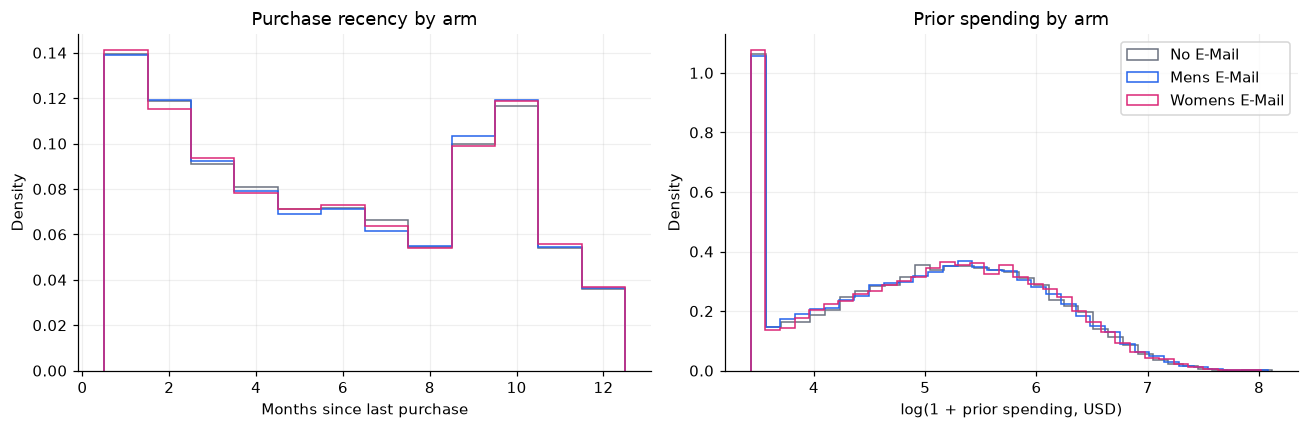

In [4]:
display(df[['recency', 'history', 'newbie', 'mens', 'womens', 'visit', 'conversion', 'spend']]
        .describe(percentiles=[0.5, 0.9, 0.99]).T)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for arm, color in zip(arm_order, colors):
    group = df[df['segment'] == arm]
    axes[0].hist(group['recency'], bins=np.arange(0.5, 13.5, 1), density=True,
                 histtype='step', label=arm, color=color)
    axes[1].hist(np.log1p(group['history']), bins=35, density=True,
                 histtype='step', label=arm, color=color)
axes[0].set(xlabel='Months since last purchase', ylabel='Density', title='Purchase recency by arm')
axes[1].set(xlabel='log(1 + prior spending, USD)', ylabel='Density', title='Prior spending by arm')
axes[1].legend()
plt.tight_layout()
plt.show()

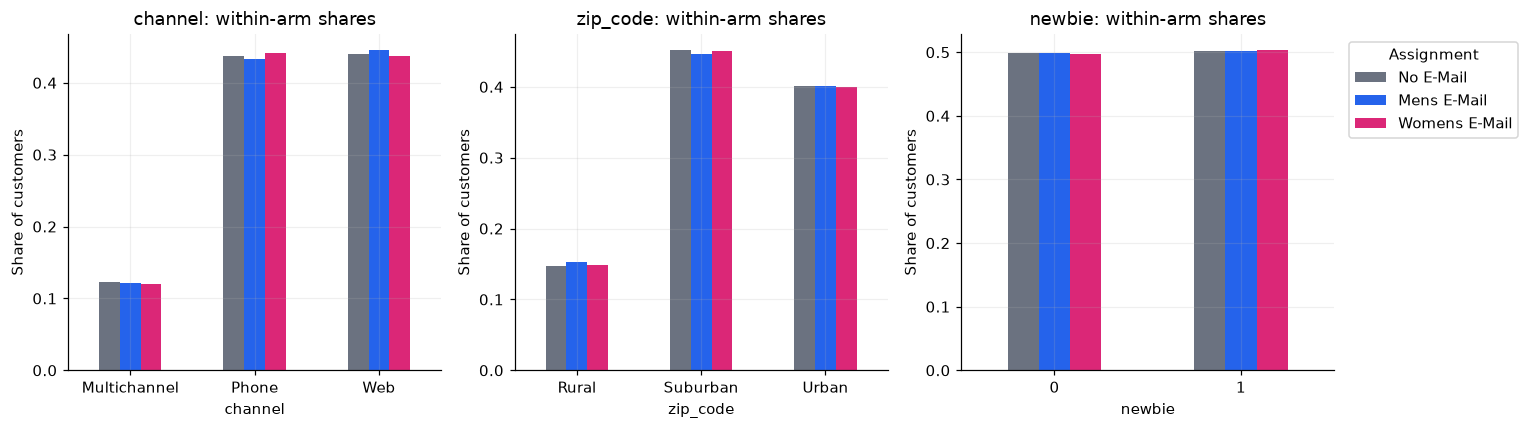

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for column, ax in zip(['channel', 'zip_code', 'newbie'], axes):
    shares = pd.crosstab(df[column], df['segment'], normalize='columns')[arm_order]
    shares.plot.bar(ax=ax, color=colors, rot=0)
    ax.set(title=f'{column}: within-arm shares', ylabel='Share of customers', xlabel=column)
    ax.get_legend().remove()
axes[-1].legend(title='Assignment', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

,arm,n_customers,share_of_sample,visits,visit_rate,visit_rate_ci_low,visit_rate_ci_high,conversions,conversion_rate,conversion_rate_ci_low,conversion_rate_ci_high,conversion_rate_per_1k,visit_to_conversion_rate,spend_total,spend_per_customer,spend_ci_low,spend_ci_high,spend_per_converter,spend_sd,spend_skewness,share_zero_spend
0,No E-Mail,21306,0.332906,2262,0.106167,0.102102,0.110375,122,0.005726,0.004798,0.006832,5.726087,0.053935,13908.33,0.652789,0.497179,0.808399,114.002705,11.588200,26.367582,0.994274
1,Mens E-Mail,21307,0.332922,3894,0.182757,0.177625,0.188003,267,0.012531,0.011123,0.014115,12.531093,0.068567,30311.69,1.422617,1.184213,1.661020,113.526929,17.754205,17.984341,0.987469
2,Womens E-Mail,21387,0.334172,3238,0.151400,0.146659,0.156267,189,0.008837,0.007668,0.010183,8.837144,0.058369,23038.11,1.077202,0.874602,1.279801,121.894762,15.116106,19.728250,0.991163


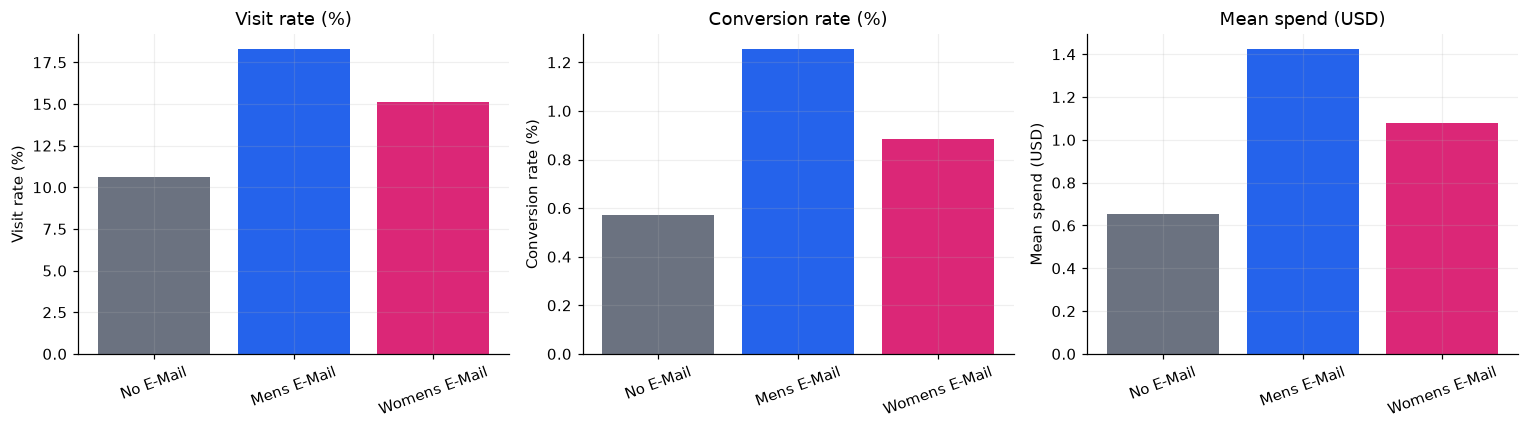

In [6]:
summary = ex.arm_summary(df).set_index('arm').loc[arm_order].reset_index()
display(summary)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for column, label, scale, ax in zip(['visit_rate', 'conversion_rate', 'spend_per_customer'],
                                  ['Visit rate (%)', 'Conversion rate (%)', 'Mean spend (USD)'],
                                  [100, 100, 1], axes):
    ax.bar(summary['arm'], scale * summary[column], color=colors)
    ax.set(ylabel=label, title=label)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

,scope,n,mean,sd,share_zero,share_positive,skewness,excess_kurtosis,p99,max,positive_mean,positive_skewness
0,pooled,64000,1.050908,15.036448,0.990969,0.009031,20.590559,510.989390,0.00,499.0,116.363547,1.760978
1,No E-Mail,21306,0.652789,11.588200,0.994274,0.005726,26.367582,854.624934,0.00,499.0,114.002705,1.994670
2,Mens E-Mail,21307,1.422617,17.754205,0.987469,0.012531,17.984341,383.621510,29.99,499.0,113.526929,1.773496
3,Womens E-Mail,21387,1.077202,15.116106,0.991163,0.008837,19.728250,473.418668,0.00,499.0,121.894762,1.642504


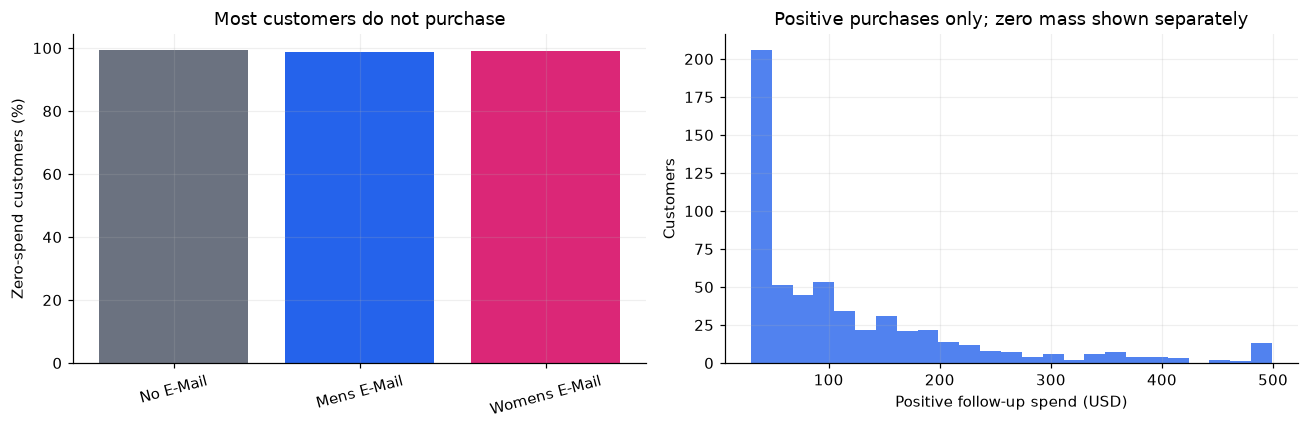

**Distribution diagnosis:** 99.10% zero spend, pooled skewness 20.6. Keep zeros when estimating average spend; use bootstrap uncertainty rather than trim large orders.

In [7]:
spend_description = pd.DataFrame([
    {'scope': 'pooled', **ex.distribution_report(df['spend'])},
    *[{'scope': arm, **ex.distribution_report(df.loc[df['segment'] == arm, 'spend'])}
      for arm in arm_order]
])
display(spend_description)
positive_spend = df.loc[df['spend'] > 0, 'spend']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
zero_shares = df.groupby('segment', observed=True)['spend'].apply(lambda s: (s == 0).mean())
axes[0].bar(arm_order, 100 * zero_shares.loc[arm_order], color=colors)
axes[0].set(ylabel='Zero-spend customers (%)', title='Most customers do not purchase')
axes[0].tick_params(axis='x', rotation=15)
axes[1].hist(positive_spend, bins=25, color='#2563eb', alpha=0.8)
axes[1].set(xlabel='Positive follow-up spend (USD)', ylabel='Customers',
            title='Positive purchases only; zero mass shown separately')
plt.tight_layout()
plt.show()
display(Markdown(f"**Distribution diagnosis:** {100 * (df.spend == 0).mean():.2f}% zero spend, "
                 f"pooled skewness {stats.skew(df.spend, bias=False):.1f}. "
                 'Keep zeros when estimating average spend; use bootstrap uncertainty rather than trim large orders.'))

## 3. Randomization diagnostics and average treatment effects

The estimand for each campaign is the intention-to-treat difference
$$\Delta_Y = E[Y\mid T=1] - E[Y\mid T=0].$$
Assignment, not an inferred gender label or observed response, defines the comparison. A sample-ratio mismatch or gross pre-campaign imbalance would trigger investigation; a large p-value does **not** prove randomization was perfect. We check standardized mean differences rather than hunt for significant covariates.

,chi2,p_value,degrees_of_freedom,min_count,max_count
0,0.202531,0.903693,2.0,21306,21387


,arm,feature,level,treated_mean,control_mean,difference,std_mean_difference,within_0_1,abs_smd
20,Mens E-Mail,history_segment,2) $100 - $200,0.220162,0.226978,-0.006816,-0.016359,True,0.016359
25,Mens E-Mail,history_segment,"7) $1,000 +",0.021777,0.019525,0.002252,0.015834,True,0.015834
2,Womens E-Mail,history_segment,2) $100 - $200,0.221022,0.226978,-0.005956,-0.014286,True,0.014286
29,Mens E-Mail,zip_code,Rural,0.152204,0.147329,0.004874,0.013659,True,0.013659
30,Mens E-Mail,zip_code,Suburban,0.445910,0.451751,-0.005841,-0.011743,True,0.011743
3,Womens E-Mail,history_segment,3) $200 - $350,0.194277,0.189806,0.004471,0.011351,True,0.011351
35,Mens E-Mail,channel,Web,0.445394,0.439923,0.005471,0.011014,True,0.011014
19,Mens E-Mail,history_segment,1) $0 - $100,0.362510,0.357270,0.005240,0.010917,True,0.010917
23,Mens E-Mail,history_segment,5) $500 - $750,0.074952,0.077537,-0.002585,-0.009740,True,0.009740
6,Womens E-Mail,history_segment,"6) $750 - $1,000",0.027727,0.029194,-0.001467,-0.008819,True,0.008819


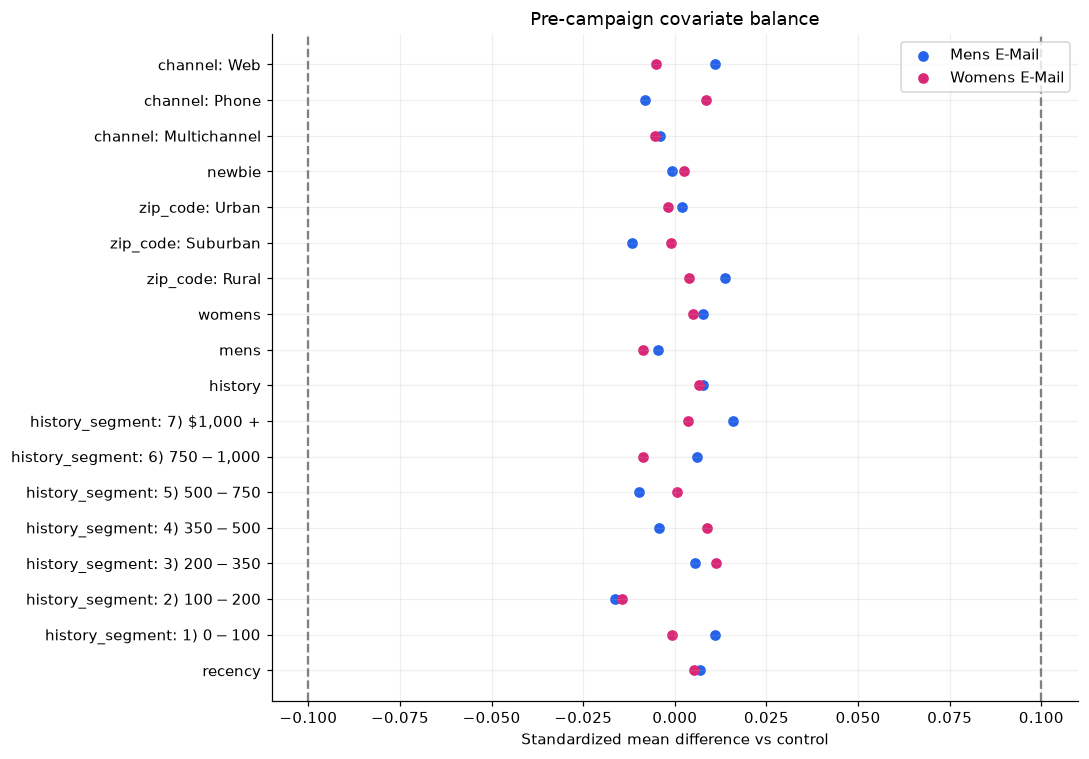

In [8]:
srm = ex.sample_ratio_test(df, expected_share=float(experiment['srm']['expected_shares']))
display(pd.DataFrame([srm]))
balance = ex.balance_table(df, FEATURE_COLUMNS, modelling['features']['categorical'])
display(balance.assign(abs_smd=balance.std_mean_difference.abs())
        .sort_values('abs_smd', ascending=False).head(12))
balance['label'] = balance['feature'] + balance['level'].fillna('').map(lambda v: f': {v}' if v else '')
fig, ax = plt.subplots(figsize=(10, 7))
for arm, color in zip(arm_order[1:], colors[1:]):
    rows = balance[balance['arm'] == arm]
    ax.scatter(rows['std_mean_difference'], rows['label'], color=color, label=arm)
ax.axvline(-0.1, ls='--', color='gray')
ax.axvline(0.1, ls='--', color='gray')
ax.set(xlabel='Standardized mean difference vs control', title='Pre-campaign covariate balance')
ax.legend()
plt.tight_layout()
plt.show()

### Inference plan and multiplicity

Conversion is primary. Visits and spend are secondary and interpreted separately. Within **each outcome** there are two campaigns reading against one control: Holm controls that two-test family. This does not control every exploratory question in the notebook as a single family.

Binary effects use the pooled two-proportion test and pointwise Wald intervals, with Newcombe score intervals as a cross-check. Spend uses a percentile bootstrap because the outcome is mostly zeros with a long positive tail. Bonferroni-dual **97.5% individual intervals** provide at least 95% simultaneous coverage across the two comparisons for an outcome. Relative lift is not interchangeable with percentage-point lift.

,comparison,outcome,mean_control,mean_treatment,effect,ci_low,ci_high,p_value,p_holm,ci_low_fwer,ci_high_fwer,method
0,mens_vs_control,conversion,0.005726,0.012531,0.006805,0.005000,0.008610,1.523224e-13,3.046447e-13,0.004741,0.008869,"Wald z test, pooled variance"
2,mens_vs_control,visit,0.106167,0.182757,0.076590,0.069954,0.083226,5.685165e-112,1.137033e-111,0.069001,0.084179,"Wald z test, pooled variance"
5,mens_vs_control,spend,0.652789,1.422617,0.769827,0.483716,1.052473,1.999800e-04,3.999600e-04,0.442881,1.093308,"percentile bootstrap, 10000 replicates (p floo..."
6,womens_vs_control,conversion,0.005726,0.008837,0.003111,0.001499,0.004723,1.571051e-04,1.571051e-04,0.001267,0.004955,"Wald z test, pooled variance"
8,womens_vs_control,visit,0.106167,0.151400,0.045233,0.038894,0.051572,3.182403e-44,3.182403e-44,0.037984,0.052483,"Wald z test, pooled variance"
11,womens_vs_control,spend,0.652789,1.077202,0.424412,0.171853,0.682885,9.999000e-04,9.999000e-04,0.135162,0.719575,"percentile bootstrap, 10000 replicates (p floo..."


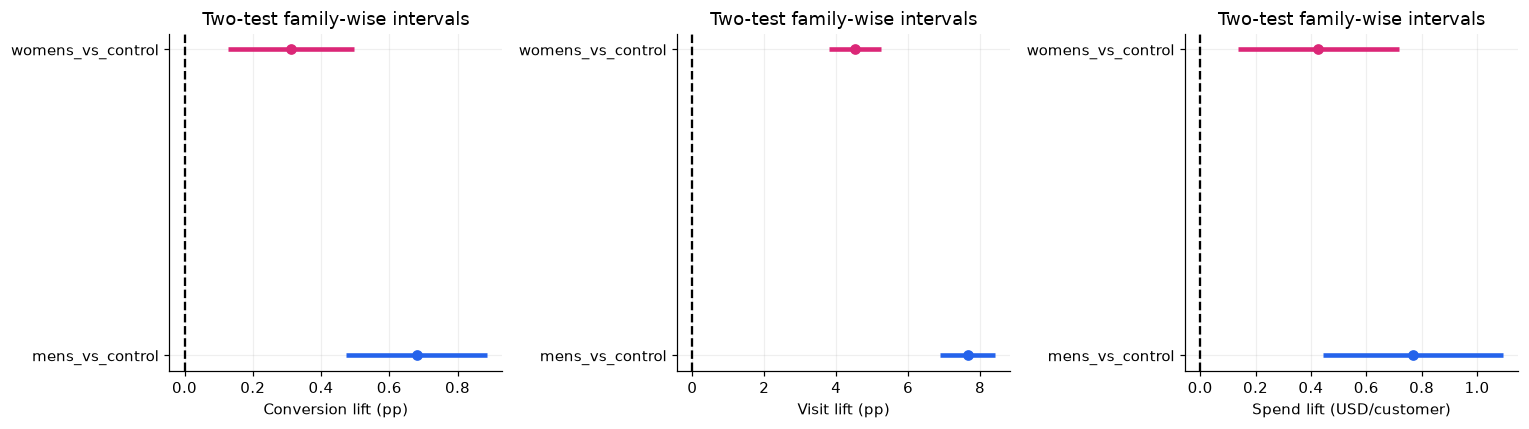

In [9]:
effects = ex.run_experiment_analysis(df, config)
headline = effects.loc[effects['confirmatory']].copy()
display(headline[['comparison', 'outcome', 'mean_control', 'mean_treatment', 'effect',
                  'ci_low', 'ci_high', 'p_value', 'p_holm', 'ci_low_fwer', 'ci_high_fwer', 'method']])
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for outcome, scale, label, ax in zip(['conversion', 'visit', 'spend'], [100, 100, 1],
                                   ['Conversion lift (pp)', 'Visit lift (pp)', 'Spend lift (USD/customer)'], axes):
    rows = headline[headline['outcome'] == outcome].reset_index(drop=True)
    for i, row in rows.iterrows():
        ax.hlines(i, scale * row.ci_low_fwer, scale * row.ci_high_fwer, color=colors[i+1], lw=3)
        ax.plot(scale * row.effect, i, 'o', color=colors[i+1])
    ax.axvline(0, color='black', ls='--')
    ax.set(yticks=range(len(rows)), yticklabels=rows['comparison'], xlabel=label,
           title='Two-test family-wise intervals')
plt.tight_layout()
plt.show()

In [10]:
conversion_results = headline[headline['outcome'] == 'conversion']
for row in conversion_results.itertuples():
    display(Markdown(f"**{row.comparison}:** conversion rises from {100 * row.mean_control:.3f}% "
                     f"to {100 * row.mean_treatment:.3f}%: **{100 * row.effect:+.3f} percentage points**, "
                     f"or {100 * row.effect / row.mean_control:+.1f}% relative lift. "
                     f"Family-wise interval [{100 * row.ci_low_fwer:+.3f}, {100 * row.ci_high_fwer:+.3f}] pp; "
                     f"Holm p = {row.p_holm:.3g}."))
score_intervals = effects[(effects['outcome'] == 'conversion') & effects['confirmatory']]
display(score_intervals[['comparison', 'ci_low', 'ci_high', 'ci_low_crosscheck',
                         'ci_high_crosscheck', 'crosscheck_method']])

**mens_vs_control:** conversion rises from 0.573% to 1.253%: **+0.681 percentage points**, or +118.8% relative lift. Family-wise interval [+0.474, +0.887] pp; Holm p = 3.05e-13.

**womens_vs_control:** conversion rises from 0.573% to 0.884%: **+0.311 percentage points**, or +54.3% relative lift. Family-wise interval [+0.127, +0.495] pp; Holm p = 0.000157.

,comparison,ci_low,ci_high,ci_low_crosscheck,ci_high_crosscheck,crosscheck_method
0,mens_vs_control,0.005000,0.008610,0.005014,0.008641,Newcombe hybrid score
6,womens_vs_control,0.001499,0.004723,0.001502,0.004745,Newcombe hybrid score


### What produces incremental spending?

Use the identity $E[S]=P(C=1)E[S\mid C=1]$. The change can be written as a conversion-rate component plus a basket-size component. This is a descriptive accounting decomposition, **not** a separate causal effect on buyer basket size: conditioning on purchasing selects a post-treatment group.

In [11]:
decomposition = pd.DataFrame([
    {'comparison': c['name'], **ex.spend_decomposition(df, c['treatment'], c['control'])}
    for c in experiment['comparisons']
])
display(decomposition)
assert np.allclose(decomposition['identity_residual'], 0, atol=1e-10)
for row in decomposition.itertuples():
    display(Markdown(f"**{row.comparison}:** {100 * row.conversion_driven_share:.1f}% of the "
                     'net spend increase is attributed to extra buyers under this decomposition. '
                     'A share above 100% means the basket component offsets part of that increase.'))

,comparison,conversion_rate_treatment,conversion_rate_control,mean_spend_per_converter_treatment,mean_spend_per_converter_control,n_converters_treatment,n_converters_control,total_spend_effect,conversion_driven_part,basket_driven_part,identity_residual,conversion_driven_share,basket_p_value,basket_ci_low,basket_ci_high
0,mens_vs_control,0.012531,0.005726,113.526929,114.002705,267,122,0.769827,0.775789,-0.005962,2.229120e-16,1.007745,0.967215,-23.249960,22.298408
1,womens_vs_control,0.008837,0.005726,121.894762,114.002705,189,122,0.424412,0.354669,0.069743,1.665335e-16,0.835671,0.514522,-15.916267,31.700381


**mens_vs_control:** 100.8% of the net spend increase is attributed to extra buyers under this decomposition. A share above 100% means the basket component offsets part of that increase.

**womens_vs_control:** 83.6% of the net spend increase is attributed to extra buyers under this decomposition. A share above 100% means the basket component offsets part of that increase.

### Robustness: covariate-adjusted models

Randomization already identifies the unadjusted comparison. A linear probability model (conversion) and OLS mean-shift model (spend) with HC1 robust standard errors provide same-scale sensitivity checks. A logistic model estimates a **log odds ratio**, not a percentage-point risk difference. These supplementary regressions are not another set of headline confirmatory discoveries.

In [12]:
covariates = list(FEATURE_COLUMNS)
adjusted = pd.DataFrame([
    {'comparison': c['name'],
     **ex.regression_adjusted_effect(df, outcome, c['treatment'], covariates, c['control'], model)}
    for c in experiment['comparisons']
    for outcome, model in [('conversion', 'ols'), ('conversion', 'logit'), ('spend', 'ols')]
])
display(adjusted[['comparison', 'outcome', 'model', 'effect_scale', 'unadjusted_effect_same_scale',
                  'adjusted_effect', 'adjusted_ci_low', 'adjusted_ci_high', 'adjusted_odds_ratio']])

,comparison,outcome,model,effect_scale,unadjusted_effect_same_scale,adjusted_effect,adjusted_ci_low,adjusted_ci_high,adjusted_odds_ratio
0,mens_vs_control,conversion,ols,risk difference,0.006805,0.006762,0.004960,0.008564,NaN
1,mens_vs_control,conversion,logit,log odds ratio,0.006805,0.787026,0.571724,1.002329,2.196854
2,mens_vs_control,spend,ols,USD per customer,0.769827,0.765344,0.480651,1.050037,NaN
3,womens_vs_control,conversion,ols,risk difference,0.003111,0.003119,0.001505,0.004734,NaN
4,womens_vs_control,conversion,logit,log odds ratio,0.003111,0.441111,0.212400,0.669821,1.554433
5,womens_vs_control,spend,ols,USD per customer,0.424412,0.425846,0.170338,0.681353,NaN


## 4. Exploratory heterogeneity and future experiment power

### Which customer groups show different estimated effects?

The subgroup variables were measured before assignment. Per-group 95% intervals are **exploratory and unadjusted**. A significant effect in one group and a nonsignificant effect in another does not establish a difference between them. Instead, compare an additive binomial model with a model containing treatment-by-group interactions and adjust **all 12 interaction tests together** with Holm. This tests heterogeneity on the logistic model's scale, which is not identical to a risk-difference interaction.

In [13]:
subgroup_frames, interaction_rows = [], []
for c in experiment['comparisons']:
    group_effects = ex.subgroup_effects(df, experiment['subgroups']['variables'],
                                      c['treatment'], c['control'], 'conversion', alpha)
    group_effects.insert(0, 'comparison', c['name'])
    subgroup_frames.append(group_effects)
    for column in experiment['subgroups']['variables']:
        interaction_rows.append({'comparison': c['name'],
                                 **ex.heterogeneity_test(df, column, c['treatment'], c['control'])})
subgroups = pd.concat(subgroup_frames, ignore_index=True)
interactions = pd.DataFrame(interaction_rows)
holm = ex.holm_adjust(interactions['p_value'], alpha)
interactions['p_holm'] = holm.p_adjusted.to_numpy()
interactions['reject_holm'] = holm.reject_adjusted.to_numpy()
display(interactions.sort_values('p_holm'))
display(subgroups[subgroups['subgroup_variable'] == 'newbie']
        [['comparison', 'subgroup', 'n_treatment', 'n_control', 'effect', 'ci_low', 'ci_high']])

,comparison,chi2,p_value,degrees_of_freedom,n_levels_tested,outcome,subgroup_variable,p_holm,reject_holm
9,womens_vs_control,10.387814,0.001268,1.0,1.0,conversion,newbie,0.015222,True
3,mens_vs_control,4.904872,0.026781,1.0,1.0,conversion,newbie,0.294591,False
8,womens_vs_control,13.732706,0.032769,6.0,6.0,conversion,history_segment,0.310749,False
11,womens_vs_control,4.648818,0.031075,1.0,1.0,conversion,womens,0.310749,False
10,womens_vs_control,4.183467,0.040820,1.0,1.0,conversion,mens,0.326561,False
0,mens_vs_control,1.916533,0.383557,2.0,2.0,conversion,zip_code,1.000000,False
1,mens_vs_control,0.451687,0.797843,2.0,2.0,conversion,channel,1.000000,False
2,mens_vs_control,3.362829,0.762121,6.0,6.0,conversion,history_segment,1.000000,False
7,womens_vs_control,1.640563,0.440308,2.0,2.0,conversion,channel,1.000000,False
6,womens_vs_control,0.261345,0.877505,2.0,2.0,conversion,zip_code,1.000000,False


,comparison,subgroup,n_treatment,n_control,effect,ci_low,ci_high
9,mens_vs_control,1,10686,10695,0.007396,0.005094,0.009698
12,mens_vs_control,0,10621,10611,0.006207,0.003424,0.008990
23,womens_vs_control,1,10763,10695,0.005272,0.003145,0.007400
34,womens_vs_control,0,10624,10611,0.000932,-0.001493,0.003357


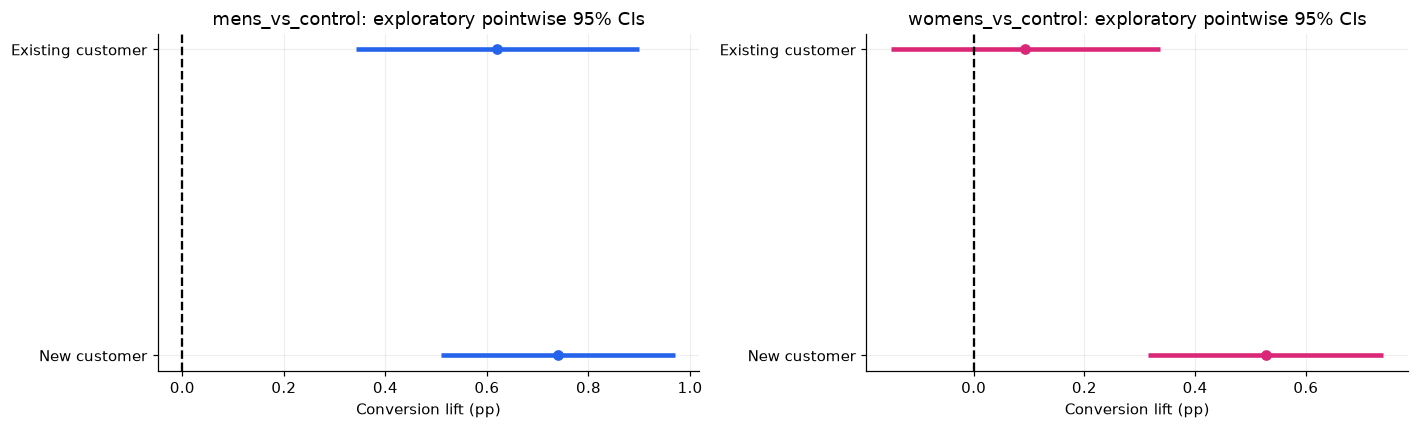

**1 of 12 interactions survive Holm adjustment.** Treat any surviving pattern as a hypothesis for a new randomized test, not a license to choose the largest noisy subgroup estimate.

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for c, ax, color in zip(experiment['comparisons'], axes, colors[1:]):
    rows = subgroups[(subgroups.comparison == c['name']) & (subgroups.subgroup_variable == 'newbie')]
    for i, row in enumerate(rows.itertuples()):
        ax.hlines(i, 100 * row.ci_low, 100 * row.ci_high, color=color, lw=3)
        ax.plot(100 * row.effect, i, 'o', color=color)
    ax.set(yticks=range(len(rows)),
           yticklabels=['New customer' if x == '1' else 'Existing customer' for x in rows.subgroup],
           xlabel='Conversion lift (pp)', title=f"{c['name']}: exploratory pointwise 95% CIs")
    ax.axvline(0, color='black', ls='--')
plt.tight_layout()
plt.show()
survivors = interactions[interactions.reject_holm]
display(Markdown(f"**{len(survivors)} of {len(interactions)} interactions survive Holm adjustment.** "
                 'Treat any surviving pattern as a hypothesis for a new randomized test, '
                 'not a license to choose the largest noisy subgroup estimate.'))

### How large should the next test be?

Use the control conversion rate as a planning baseline, a two-sided 5% family error budget split across two comparisons, and 80% target power. Below, each design has one control and two equally sized treatment arms. Sample-size formulas are approximations; simulate the same pooled z test to check rare-outcome behavior. These are planning scenarios, not retrospective evidence that a nonsignificant effect is absent.

,relative_lift,absolute_lift_pp,n_per_arm,three_arm_total,simulated_power,simulation_se
0,0.10,0.057261,346494,1039482,0.79200,0.006417
1,0.25,0.143152,59373,178119,0.78850,0.006457
2,0.50,0.286304,16480,49440,0.79500,0.006383
3,1.00,0.572609,4936,14808,0.80975,0.006206


At approximately **21,306 customers per arm**, the normal-approximation 80%-power MDE is **0.248 pp** (43.4% relative). Small nudges to this rare conversion outcome require much larger experiments.

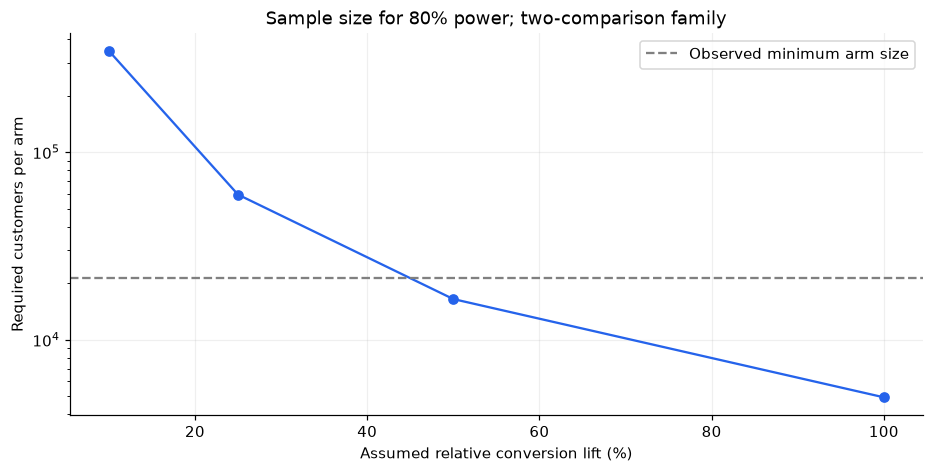

In [15]:
p_control = float(df.loc[df.segment == experiment['arms']['control'], 'conversion'].mean())
family_alpha = pw.alpha_for_family(alpha, len(experiment['comparisons']))
power_rows = []
for relative_lift in [0.10, 0.25, 0.50, 1.00]:
    p_treatment = p_control * (1 + relative_lift)
    design = pw.sample_size_two_proportions(p_control, p_treatment, alpha=family_alpha, power=0.8)
    n = int(design['n_control'])
    simulation = pw.monte_carlo_power(p_control, p_treatment, n, alpha=family_alpha, seed=seed)
    power_rows.append({'relative_lift': relative_lift, 'absolute_lift_pp': 100 * (p_treatment-p_control),
                       'n_per_arm': n, 'three_arm_total': 3*n,
                       'simulated_power': simulation['simulated_power'],
                       'simulation_se': simulation['standard_error_of_power']})
power_plan = pd.DataFrame(power_rows)
display(power_plan)
actual_n = int(df.segment.value_counts().min())
mde = pw.mde_two_proportions(p_control, actual_n, alpha=family_alpha, power=0.8)
display(Markdown(f"At approximately **{actual_n:,} customers per arm**, the normal-approximation "
                 f"80%-power MDE is **{100*mde:.3f} pp** ({100*mde/p_control:.1f}% relative). "
                 'Small nudges to this rare conversion outcome require much larger experiments.'))
fig, ax = plt.subplots()
ax.plot(100 * power_plan.relative_lift, power_plan.n_per_arm, marker='o', color='#2563eb')
ax.axhline(actual_n, ls='--', color='gray', label='Observed minimum arm size')
ax.set(xlabel='Assumed relative conversion lift (%)', ylabel='Required customers per arm',
       yscale='log', title='Sample size for 80% power; two-comparison family')
ax.legend()
plt.show()

## 5. Leakage-safe preparation and explicit ML training

### Evaluation design

The configuration fixes **Mens E-Mail vs No E-Mail**. Womens customers remain in the shared preprocessing split but are excluded from this model fit and evaluation. They are not reassigned to control. Training uses 60%, validation 20%, and test 20%, stratified on assignment and conversion. Stratification uses outcomes only to allocate rows; it does not expose test labels to model fitting.

Imputation, one-hot encoding and numeric scaling learn their state on training rows only. Prior-spend band overlaps with numeric history; gain importance must therefore not be read as an independent causal contribution. There is no class resampling or test-driven hyperparameter search.

In [16]:
splits = make_splits(df, config)
bundle = build_features(splits, config)
display(bundle.arms_per_split(splits))
cell_counts = pd.concat({name: split.groupby('segment', observed=True)['conversion']
                        .agg(customers='size', conversions='sum', conversion_rate='mean')
                        for name, split in splits.items()}, names=['split'])
display(cell_counts)
index_sets = {name: set(split.index) for name, split in splits.items()}
assert not (index_sets['train'] & index_sets['validate'])
assert not (index_sets['train'] & index_sets['test'])
assert not (index_sets['validate'] & index_sets['test'])
assert len(set.union(*index_sets.values())) == len(df)
for name, matrix in [('train', bundle.x_train), ('validate', bundle.x_validate), ('test', bundle.x_test)]:
    assert_no_leakage(matrix, name)
    assert np.isfinite(matrix.to_numpy()).all()
display(bundle.feature_name_map)
numeric_names = modelling['features']['numeric']
learned_medians = bundle.preprocessor.named_transformers_['numeric'].named_steps['imputer'].statistics_
assert np.allclose(learned_medians, splits['train'][numeric_names].median())
print(f'Training-only preprocessing confirmed: {len(bundle.feature_names)} model columns.')

segment,Womens E-Mail,Mens E-Mail,No E-Mail
train,12832,12784,12783
validate,4278,4262,4261
test,4277,4261,4262


customers  conversions  conversion_rate
split    segment                                               
train    Mens E-Mail        12784          160         0.012516
         No E-Mail          12783           73         0.005711
         Womens E-Mail      12832          113         0.008806
validate Mens E-Mail         4262           54         0.012670
         No E-Mail           4261           24         0.005632
         Womens E-Mail       4278           38         0.008883
test     Mens E-Mail         4261           53         0.012438
         No E-Mail           4262           25         0.005866
         Womens E-Mail       4277           38         0.008885

,source_label,model_column
0,recency,recency
1,history,history
2,newbie,newbie
3,mens,mens
4,womens,womens
5,history_segment_1) $0 - $100,history_segment_1_0_100
6,history_segment_2) $100 - $200,history_segment_2_100_200
7,history_segment_3) $200 - $350,history_segment_3_200_350
8,history_segment_4) $350 - $500,history_segment_4_350_500
9,history_segment_5) $500 - $750,history_segment_5_500_750


Training-only preprocessing confirmed: 18 model columns.


### Three learners, three distinct questions

| Model | Training data | Predictions used for ranking |
|---|---|---|
| Purchase-propensity baseline | Emailed training customers only | $\hat P(Y=1\mid X,T=1)$ |
| S-learner | Both arms; assignment enters as a design feature | $\hat m(X,1)-\hat m(X,0)$ from one model |
| T-learner | Separate models for each randomized arm | $\hat m_1(X)-\hat m_0(X)$ |

Here *propensity* means **purchase response**, not the probability of treatment assignment. Randomization already supplies treatment assignment; no propensity matching is needed.

LightGBM is capped at 400 trees; validation AUC stops boosting after 50 rounds without improvement. Response AUC is only a fitting diagnostic: two good response models can subtract to a poor uplift estimate. The T-learner estimates two surfaces from relatively few conversions, so its difference can be noisy.

In [17]:
params = lightgbm_params(config, seed)
patience = int(modelling['early_stopping_rounds'])
train_t = bundle.y_train.segment == comparison['treatment']
train_c = bundle.y_train.segment == comparison['control']
valid_t = bundle.y_validate.segment == comparison['treatment']
valid_c = bundle.y_validate.segment == comparison['control']
xt, xc = bundle.x_train[train_t], bundle.x_train[train_c]
yt = bundle.y_train.loc[train_t, 'conversion'].to_numpy()
yc = bundle.y_train.loc[train_c, 'conversion'].to_numpy()
vt, vc = bundle.x_validate[valid_t], bundle.x_validate[valid_c]
yvt = bundle.y_validate.loc[valid_t, 'conversion'].to_numpy()
yvc = bundle.y_validate.loc[valid_c, 'conversion'].to_numpy()
display(pd.Series(params, name='LightGBM parameters'))
print(f'Model training rows: treated={len(yt):,}, control={len(yc):,}; '
      f'conversions: treated={yt.sum()}, control={yc.sum()}')

n_estimators              400
learning_rate            0.05
num_leaves                 31
min_child_samples          40
subsample                 0.8
subsample_freq              1
colsample_bytree          0.8
reg_lambda                1.0
objective              binary
random_state         20261107
n_jobs                     -1
verbosity                  -1
importance_type          gain
Name: LightGBM parameters, dtype: object

Model training rows: treated=12,784, control=12,783; conversions: treated=160, control=73


In [18]:
propensity = PropensityModel().fit(xt, yt, vt, yvt, params, patience)
display(pd.Series(propensity.metrics, name='Purchase-propensity fit'))

train_log_loss                 0.066323
train_auc                      0.753855
train_n                         12784.0
validation_log_loss            0.067711
validation_auc                 0.567924
validation_n                     4262.0
validation_scope       emailed arm only
best_iteration                      2.0
Name: Purchase-propensity fit, dtype: object

In [19]:
s_learner = SLearner().fit(
    xt, yt, xc, yc,
    pd.concat([vt, vc]), np.concatenate([yvt, yvc]),
    np.concatenate([np.ones(len(vt)), np.zeros(len(vc))]),
    params, patience,
)
display(pd.Series(s_learner.metrics, name='S-learner fit'))

train_log_loss                 0.050163
train_auc                      0.813988
train_n                         25567.0
validation_log_loss            0.051631
validation_auc                 0.616577
validation_n                     8523.0
validation_scope       both arms pooled
n_treated_rows                  12784.0
n_control_rows                  12783.0
best_iteration                      6.0
Name: S-learner fit, dtype: object

In [20]:
t_learner = TLearner().fit(xt, yt, xc, yc, vt, yvt, vc, yvc, params, patience)
display(pd.Series(t_learner.metrics, name='T-learner fit'))
fitted_models = {'propensity': propensity, 's_learner': s_learner, 't_learner': t_learner}
fit_metrics = pd.DataFrame({name: model.metrics for name, model in fitted_models.items()}).T
display(fit_metrics)

treated_train_log_loss                 0.066323
treated_train_auc                      0.753855
treated_train_n                         12784.0
control_train_log_loss                 0.034837
control_train_auc                      0.806321
control_train_n                         12783.0
control_validation_log_loss            0.034673
control_validation_auc                 0.591028
control_validation_n                     4261.0
validation_log_loss                    0.067711
validation_auc                         0.567924
validation_n                             4262.0
validation_scope               emailed arm only
n_treated_rows                          12784.0
n_control_rows                          12783.0
best_iteration_treated                      2.0
best_iteration_control                      1.0
Name: T-learner fit, dtype: object

,train_log_loss,train_auc,train_n,validation_log_loss,validation_auc,validation_n,validation_scope,best_iteration,n_treated_rows,n_control_rows,treated_train_log_loss,treated_train_auc,treated_train_n,control_train_log_loss,control_train_auc,control_train_n,control_validation_log_loss,control_validation_auc,control_validation_n,best_iteration_treated,best_iteration_control
propensity,0.066323,0.753855,12784.0,0.067711,0.567924,4262.0,emailed arm only,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
s_learner,0.050163,0.813988,25567.0,0.051631,0.616577,8523.0,both arms pooled,6.0,12784.0,12783.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
t_learner,NaN,NaN,NaN,0.067711,0.567924,4262.0,emailed arm only,NaN,12784.0,12783.0,0.066323,0.753855,12784.0,0.034837,0.806321,12783.0,0.034673,0.591028,4261.0,2.0,1.0


**Read the fit table carefully.** The S-learner's reported validation AUC pools both arms; the propensity model and T-learner's unprefixed validation AUC use emailed customers. Those headline AUCs are not directly comparable. We therefore calculate a common emailed validation readout below. Few fitted trees are a result of the frozen early-stopping rule; we do not increase complexity after inspecting test scores.

,learner,emailed_validation_auc,emailed_validation_ap,emailed_validation_log_loss,emailed_validation_brier
0,propensity,0.567924,0.01673,0.067711,0.012504
1,s_learner,0.583936,0.01879,0.068031,0.012511
2,t_learner,0.567924,0.01673,0.067711,0.012504


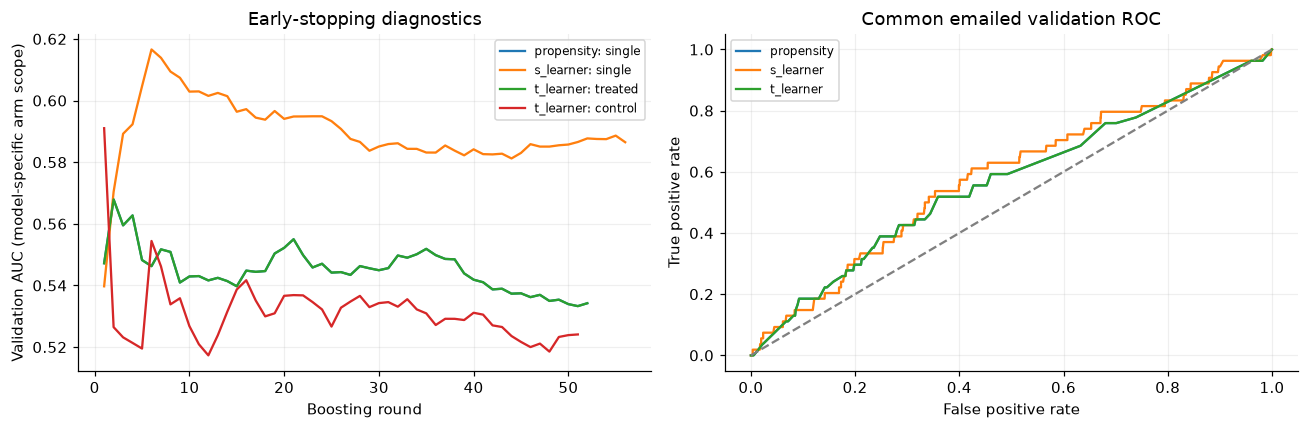

In [21]:
common_validation = []
for name, model in fitted_models.items():
    probability = model.predict(vt)['response_score'].to_numpy()
    common_validation.append({'learner': name, 'emailed_validation_auc': roc_auc_score(yvt, probability),
                              'emailed_validation_ap': average_precision_score(yvt, probability),
                              'emailed_validation_log_loss': log_loss(yvt, probability, labels=[0, 1]),
                              'emailed_validation_brier': brier_score_loss(yvt, probability)})
display(pd.DataFrame(common_validation))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, model in fitted_models.items():
    if name == 't_learner':
        curves = [('treated', model.model_treated), ('control', model.model_control)]
    else:
        curves = [('single', model.model)]
    for label, submodel in curves:
        valid_curve = submodel.evals_result_['valid_0']['auc']
        axes[0].plot(np.arange(1, len(valid_curve)+1), valid_curve, label=f'{name}: {label}')
for name, model in fitted_models.items():
    probability = model.predict(vt)['response_score'].to_numpy()
    fpr, tpr, _ = roc_curve(yvt, probability)
    axes[1].plot(fpr, tpr, label=name)
axes[0].set(xlabel='Boosting round', ylabel='Validation AUC (model-specific arm scope)',
            title='Early-stopping diagnostics')
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set(xlabel='False positive rate', ylabel='True positive rate', title='Common emailed validation ROC')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Holdout evaluation

Only fitted models predict these test rows; no test result changes the model or its hyperparameters. A response ROC answers “who purchases?” Uplift evaluation instead asks whether customers ranked highly have larger **observed treated-minus-control effects** than other customers.

An individual uplift prediction cannot be compared with a true individual uplift label: one potential outcome is missing for every customer. Calibration of response probabilities is possible; individual treatment-effect accuracy is not.

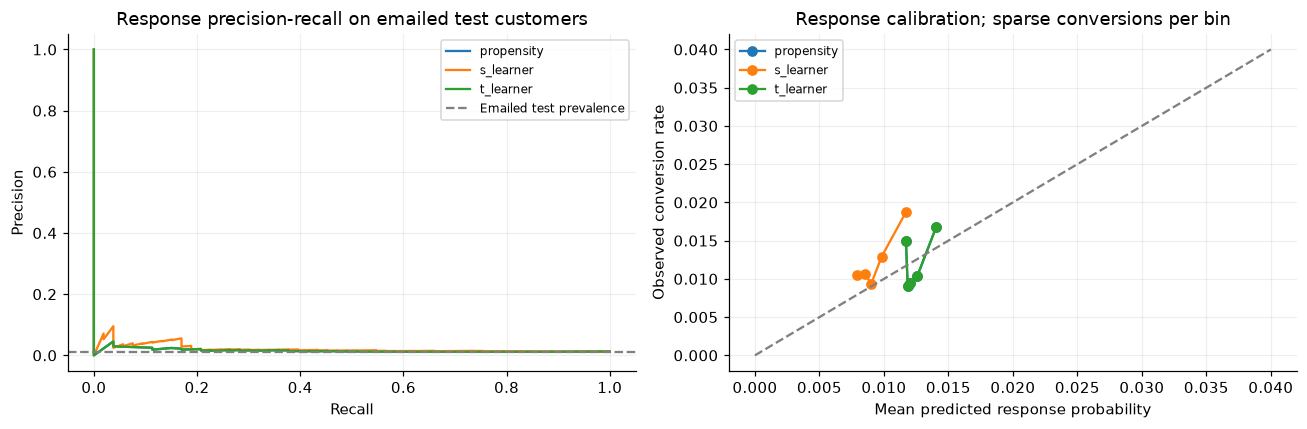

,learner,test_emailed_auc,test_emailed_ap,test_emailed_log_loss,test_emailed_brier
0,propensity,0.504690,0.016038,0.066807,0.012280
1,s_learner,0.573577,0.022299,0.066916,0.012282
2,t_learner,0.504690,0.016038,0.066807,0.012280


Two-arm holdout: 8,523 customers, 4,261 emailed; 78 conversions in both arms.


In [22]:
holdout = ev.prepare_holdout(bundle.y_test, comparison['treatment'], comparison['control'], comparison['name'])
test_scores = {name: model.predict(bundle.x_test).loc[holdout.frame.index]
               for name, model in fitted_models.items()}
emailed_test = holdout.frame.treated == 1
y_emailed_test = holdout.frame.loc[emailed_test, 'conversion'].to_numpy()
response_metrics = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, scores in test_scores.items():
    p = scores.loc[emailed_test, 'response_score'].to_numpy()
    response_metrics.append({'learner': name, 'test_emailed_auc': roc_auc_score(y_emailed_test, p),
                             'test_emailed_ap': average_precision_score(y_emailed_test, p),
                             'test_emailed_log_loss': log_loss(y_emailed_test, p, labels=[0, 1]),
                             'test_emailed_brier': brier_score_loss(y_emailed_test, p)})
    precision, recall, _ = precision_recall_curve(y_emailed_test, p)
    axes[0].plot(recall, precision, label=name)
    fraction_positive, mean_probability = calibration_curve(y_emailed_test, p, n_bins=5, strategy='quantile')
    axes[1].plot(mean_probability, fraction_positive, 'o-', label=name)
axes[0].axhline(y_emailed_test.mean(), ls='--', color='gray', label='Emailed test prevalence')
axes[0].set(xlabel='Recall', ylabel='Precision', title='Response precision-recall on emailed test customers')
axes[1].plot([0, 0.04], [0, 0.04], '--', color='gray')
axes[1].set(xlabel='Mean predicted response probability', ylabel='Observed conversion rate',
            title='Response calibration; sparse conversions per bin')
for ax in axes:
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
display(pd.DataFrame(response_metrics))
print(f'Two-arm holdout: {holdout.n:,} customers, {holdout.n_treated:,} emailed; '
      f'{holdout.frame.conversion.sum()} conversions in both arms.')

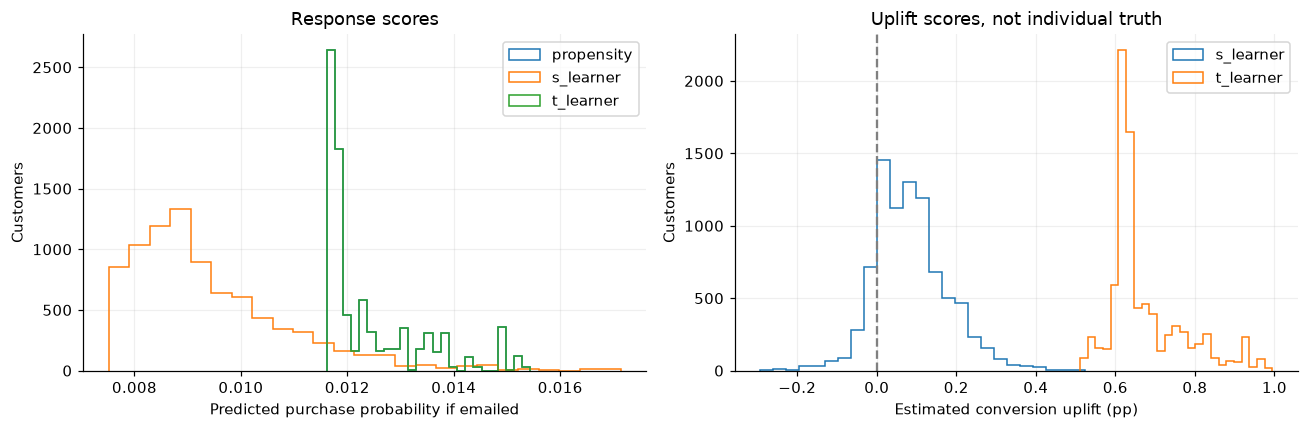

,learner,distinct_response_scores,distinct_uplift_scores,mean_uplift_score
0,propensity,87,0,NaN
1,s_learner,2039,2709,0.000866
2,t_learner,87,305,0.006735


In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, scores in test_scores.items():
    axes[0].hist(scores.response_score, bins=25, histtype='step', label=name)
    if name != 'propensity':
        axes[1].hist(100 * scores.uplift_score, bins=25, histtype='step', label=name)
axes[0].set(xlabel='Predicted purchase probability if emailed', ylabel='Customers', title='Response scores')
axes[1].axvline(0, ls='--', color='gray')
axes[1].set(xlabel='Estimated conversion uplift (pp)', ylabel='Customers', title='Uplift scores, not individual truth')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()
score_audit = pd.DataFrame([
    {'learner': name, 'distinct_response_scores': scores.response_score.nunique(),
     'distinct_uplift_scores': scores.uplift_score.nunique(),
     'mean_uplift_score': scores.uplift_score.mean()}
    for name, scores in test_scores.items()
])
display(score_audit)

### Ranking deciles and uncertainty

Rank propensity on predicted response; rank S/T learners on estimated uplift. Break tied scores with seeded, arm-independent random draws. Without this, the split's row order could accidentally sort customers by assignment. The same draw is shared in paired policy comparisons.

Each decile reports observed conversion differences and pointwise 95% Wald intervals, **not simultaneous intervals across all deciles**. These are diagnostics, not ten new confirmatory claims. Coarse early-stopped tree scores can put many customers into the same score block; differences within those ties are arbitrary.

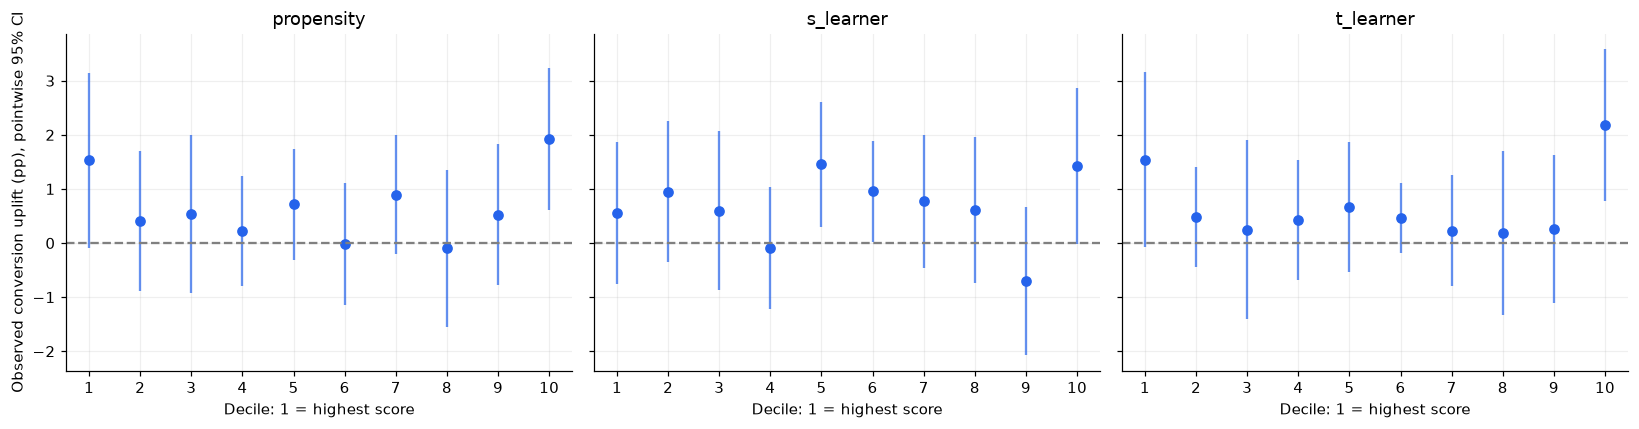

,learner,decile,n_customers,n_treated,n_control,mean_predicted_score,observed_uplift_conversion,uplift_ci_low,uplift_ci_high
0,propensity,1,853,408,445,0.014600,0.015317,-0.000836,0.031470
1,propensity,2,852,440,412,0.013541,0.004082,-0.008782,0.016946
2,propensity,3,852,413,439,0.012840,0.005416,-0.009150,0.019982
3,propensity,4,853,432,421,0.012338,0.002194,-0.008027,0.012415
4,propensity,5,852,422,430,0.011997,0.007153,-0.003152,0.017458
5,propensity,6,852,432,420,0.011886,-0.000198,-0.011432,0.011035
6,propensity,7,853,440,413,0.011826,0.008942,-0.002037,0.019922
7,propensity,8,852,443,409,0.011729,-0.000938,-0.015436,0.013559
8,propensity,9,852,414,438,0.011721,0.005228,-0.007825,0.018281
9,propensity,10,852,417,435,0.011685,0.019185,0.006019,0.032351


In [24]:
rankings = {name: scores['response_score' if name == 'propensity' else 'uplift_score']
            for name, scores in test_scores.items()}
deciles = {name: ev.decile_table(holdout, ranking, n_bins=10, alpha=alpha,
                                seed=int(bootstrap_cfg['seed']))
           for name, ranking in rankings.items()}
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for (name, table), ax in zip(deciles.items(), axes):
    for row in table.itertuples():
        ax.vlines(row.decile, 100*row.uplift_ci_low, 100*row.uplift_ci_high, color='#2563eb', alpha=0.7)
        ax.plot(row.decile, 100*row.observed_uplift_conversion, 'o', color='#2563eb')
    ax.axhline(0, ls='--', color='gray')
    ax.set(xlabel='Decile: 1 = highest score', title=name, xticks=range(1, 11))
axes[0].set_ylabel('Observed conversion uplift (pp), pointwise 95% CI')
plt.tight_layout()
plt.show()
deciles_all = pd.concat(deciles, names=['learner']).reset_index(level=0).reset_index(drop=True)
display(deciles_all[['learner', 'decile', 'n_customers', 'n_treated', 'n_control',
                     'mean_predicted_score', 'observed_uplift_conversion', 'uplift_ci_low', 'uplift_ci_high']])
assert (deciles_all.n_treated > 0).all() and (deciles_all.n_control > 0).all()

### Cumulative gain and Qini

At each cumulative decile cutoff, calculate
$$G(k)=\sum_{T=1,\ top\ k}Y-\frac{n_{T,k}}{n_{C,k}}\sum_{T=0,\ top\ k}Y.$$
The diagonal joins zero to the whole-holdout gain. Our reported Qini coefficient is the trapezoidal area **between this gain curve and that diagonal**. Raw gain AUC is also shown. This is a decile-resolution convention in outcome units, not a normalized Qini score or an individual accuracy metric. Curves alone have no confidence bands here; paired bootstrap inference below addresses selected policy contrasts.

,learner,gain_curve_auc_conversions,qini_coefficient_conversions,qini_coefficient_spend_usd,top_decile_uplift_conversion,bottom_decile_uplift_conversion,top_minus_bottom,top_decile_uplift_spend,bottom_decile_uplift_spend,monotonic_by_decile
0,propensity,13.364247,-0.638685,98.421538,0.015317,0.019185,-0.003867,1.360213,2.072734,False
1,s_learner,13.942517,-0.060416,150.207523,0.005513,0.014297,-0.008784,0.911600,2.281525,False
2,t_learner,13.252614,-0.750319,99.837758,0.015387,0.021739,-0.006353,1.369279,1.224469,False


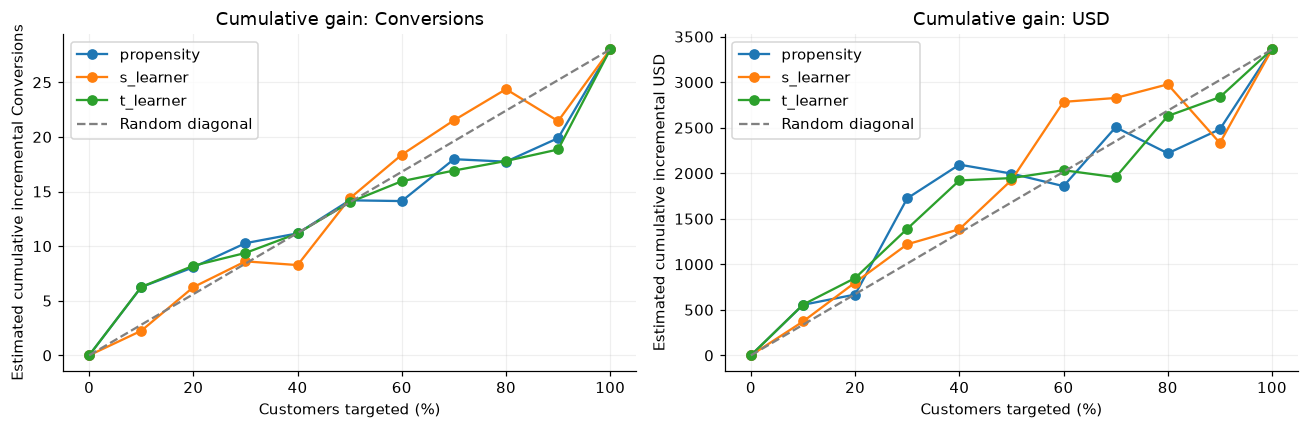

In [25]:
conversion_curves = {name: ev.cumulative_targeting_curve(table, 'conversion') for name, table in deciles.items()}
spend_curves = {name: ev.cumulative_targeting_curve(table, 'spend') for name, table in deciles.items()}
ranking_metrics = pd.DataFrame([
    {'learner': name, 'gain_curve_auc_conversions': ev.area_under_curve(conversion_curves[name]),
     'qini_coefficient_conversions': ev.qini_coefficient(conversion_curves[name]),
     'qini_coefficient_spend_usd': ev.qini_coefficient(spend_curves[name]),
     **ev.decile_spread(deciles[name])}
    for name in deciles
])
display(ranking_metrics)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for curves, ax, unit in zip([conversion_curves, spend_curves], axes, ['Conversions', 'USD']):
    for name, curve in curves.items():
        ax.plot(100*curve.share_targeted, curve.qini_gain, marker='o', label=name)
    first = next(iter(curves.values()))
    ax.plot(100*first.share_targeted, first.random_line_gain, '--', color='gray', label='Random diagonal')
    ax.set(xlabel='Customers targeted (%)', ylabel=f'Estimated cumulative incremental {unit}',
           title=f'Cumulative gain: {unit}')
    ax.legend()
plt.tight_layout()
plt.show()

**Interpretation:** A positive average campaign effect can coexist with a poor targeting model. All conversion Qini coefficients in the original run were negative. That means no demonstrated improvement over the random diagonal under this metric, not that the campaign itself harms customers. Spending is secondary and noisy; a positive spending-area statistic does not rescue an unsuccessful primary-conversion targeting result.

### Fixed-budget policy values and paired comparisons

The budget grid is frozen in configuration. For each ranking, estimate the selected slice's treated-minus-control conversion/spend rate. Multiplying that rate by **the number actually treated in the randomized slice** gives the incremental totals below. These are not totals for mailing every selected customer in a future deployment; the denominator is stated explicitly.

Lists overlap. Subtracting two separate confidence intervals is not a confidence interval for their difference. A paired customer bootstrap reranks both lists in each resample and computes the difference. The intervals are pointwise across budgets and strategies; do not select the best budget afterward and treat it as a confirmatory win. The customer bootstrap does not include training-set/model-fit uncertainty.

,strategy,share_targeted,n_selected,n_selected_treated,uplift_conversion_per_customer,incremental_conversions_in_slice,incremental_spend_in_slice_usd,uplift_spend_ci_low,uplift_spend_ci_high
0,propensity,0.05,426,204,0.010996,2.243243,331.137568,-3.524739,7.837969
1,propensity,0.10,852,408,0.015302,6.243243,553.847568,-1.232267,4.550934
2,propensity,0.20,1705,848,0.009508,8.063011,667.616079,-0.945867,2.705784
3,propensity,0.30,2557,1261,0.008144,10.270062,1724.344383,-0.107843,2.885085
4,propensity,0.50,4262,2115,0.006711,14.193759,1996.300461,-0.043981,1.915901
5,propensity,0.75,6392,3216,0.004893,15.735516,2257.546171,-0.034654,1.440036
6,propensity,1.00,8523,4261,0.006573,28.005866,3359.391940,0.173300,1.440905
7,s_learner,0.05,426,208,0.000441,0.091743,-125.171101,-2.904229,0.878679
8,s_learner,0.10,852,408,0.005498,2.243243,371.394595,-0.812027,3.138374
9,s_learner,0.20,1705,831,0.007516,6.245995,799.898078,-0.146872,2.229425


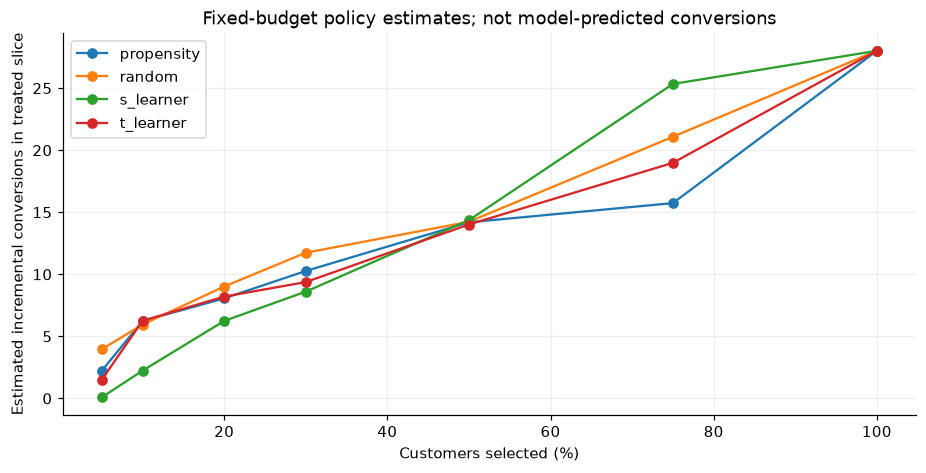

In [26]:
strategies = {**rankings, 'random': ev.random_strategy(holdout, seed)}
budgets = [float(b) for b in modelling['targeting']['budget_levels']]
policies = ev.policy_table(holdout, strategies, budgets, bootstrap_cfg, alpha)
display(policies[['strategy', 'share_targeted', 'n_selected', 'n_selected_treated',
                  'uplift_conversion_per_customer', 'incremental_conversions_in_slice',
                  'incremental_spend_in_slice_usd', 'uplift_spend_ci_low', 'uplift_spend_ci_high']])
fig, ax = plt.subplots()
for name, group in policies.groupby('strategy'):
    ax.plot(100*group.share_targeted, group.incremental_conversions_in_slice, 'o-', label=name)
ax.set(xlabel='Customers selected (%)', ylabel='Estimated incremental conversions in treated slice',
       title='Fixed-budget policy estimates; not model-predicted conversions')
ax.legend()
plt.show()

,comparator,share_targeted,incremental_conversions_difference,difference_ci_low,difference_ci_high,incremental_spend_difference_usd,spend_difference_ci_low,spend_difference_ci_high
0,propensity,0.05,-0.728222,-3.657308,0.726162,19.113076,-77.427387,150.454658
1,propensity,0.10,0.012937,-0.164650,0.210326,2.337286,-30.038144,37.427071
2,propensity,0.20,0.142704,-3.803801,4.859281,181.227464,-329.464456,730.641961
3,propensity,0.30,-0.894006,-3.000000,1.787570,-334.687652,-1044.360000,52.588817
4,propensity,0.50,-0.180626,-5.275479,4.533208,-49.624232,-488.655630,316.009615
5,propensity,0.75,3.244446,-5.588674,10.679466,253.645538,-1181.933305,641.583483
6,propensity,1.00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
7,random,0.05,-2.447064,-9.051428,4.459684,235.992871,-837.983388,1558.132390
8,random,0.10,0.298733,-8.749947,9.126685,-174.507983,-1751.411052,1334.317104
9,random,0.20,-0.811850,-11.309171,9.873449,220.667149,-1581.748634,1956.042678


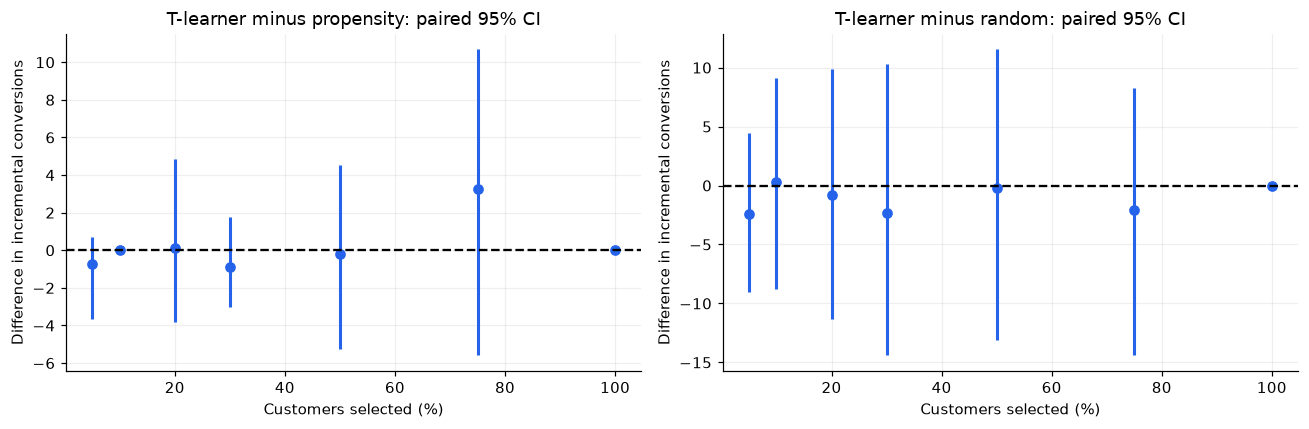

In [27]:
paired_cfg = {**bootstrap_cfg, 'replicates': int(bootstrap_cfg['replicates_small'])}
paired_rows = []
for comparator in ['propensity', 'random']:
    for budget in budgets:
        paired_rows.append({'comparator': comparator,
                            **ev.targeting_comparison(holdout, rankings['t_learner'], strategies[comparator],
                                                       budget, paired_cfg, alpha)})
paired = pd.DataFrame(paired_rows)
display(paired[['comparator', 'share_targeted', 'incremental_conversions_difference',
                'difference_ci_low', 'difference_ci_high', 'incremental_spend_difference_usd',
                'spend_difference_ci_low', 'spend_difference_ci_high']])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for comparator, ax in zip(['propensity', 'random'], axes):
    group = paired[paired.comparator == comparator]
    for row in group.itertuples():
        ax.vlines(100*row.share_targeted, row.difference_ci_low, row.difference_ci_high,
                  color='#2563eb', lw=2)
        ax.plot(100*row.share_targeted, row.incremental_conversions_difference, 'o', color='#2563eb')
    ax.axhline(0, color='black', ls='--')
    ax.set(xlabel='Customers selected (%)', ylabel='Difference in incremental conversions',
           title=f'T-learner minus {comparator}: paired 95% CI')
plt.tight_layout()
plt.show()

In [28]:
for budget in budgets:
    row = paired[(paired.comparator == 'propensity') & (paired.share_targeted == budget)].iloc[0]
    a = policies[(policies.strategy == 't_learner') & (policies.share_targeted == budget)].iloc[0]
    b = policies[(policies.strategy == 'propensity') & (policies.share_targeted == budget)].iloc[0]
    assert np.isclose(row.incremental_conversions_difference,
                      a.incremental_conversions_in_slice-b.incremental_conversions_in_slice)
full_list = policies[policies.share_targeted == 1.0]
assert full_list.uplift_conversion_per_customer.max()-full_list.uplift_conversion_per_customer.min() < 1e-12
first_budget = paired[(paired.comparator == 'propensity') & (paired.share_targeted == budgets[0])].iloc[0]
display(Markdown(f"At **{100*budgets[0]:.0f}% targeted**, T-learner minus propensity is "
                 f"**{first_budget.incremental_conversions_difference:+.2f} conversions** "
                 f"[{first_budget.difference_ci_low:+.2f}, {first_budget.difference_ci_high:+.2f}]. "
                 'Full-list policies converge because ranking is irrelevant when everyone is selected.'))

At **5% targeted**, T-learner minus propensity is **-0.73 conversions** [-3.66, +0.73]. Full-list policies converge because ranking is irrelevant when everyone is selected.

### What features are the models using?

Gain importance measures how much a feature contributed to the fitted response-tree splits. It is not a causal explanation and averaging treated/control gain is **not uplift-specific importance**. Correlated history representations can share importance. We inspect this to understand fitted response surfaces, not to claim a customer characteristic causes responsiveness.

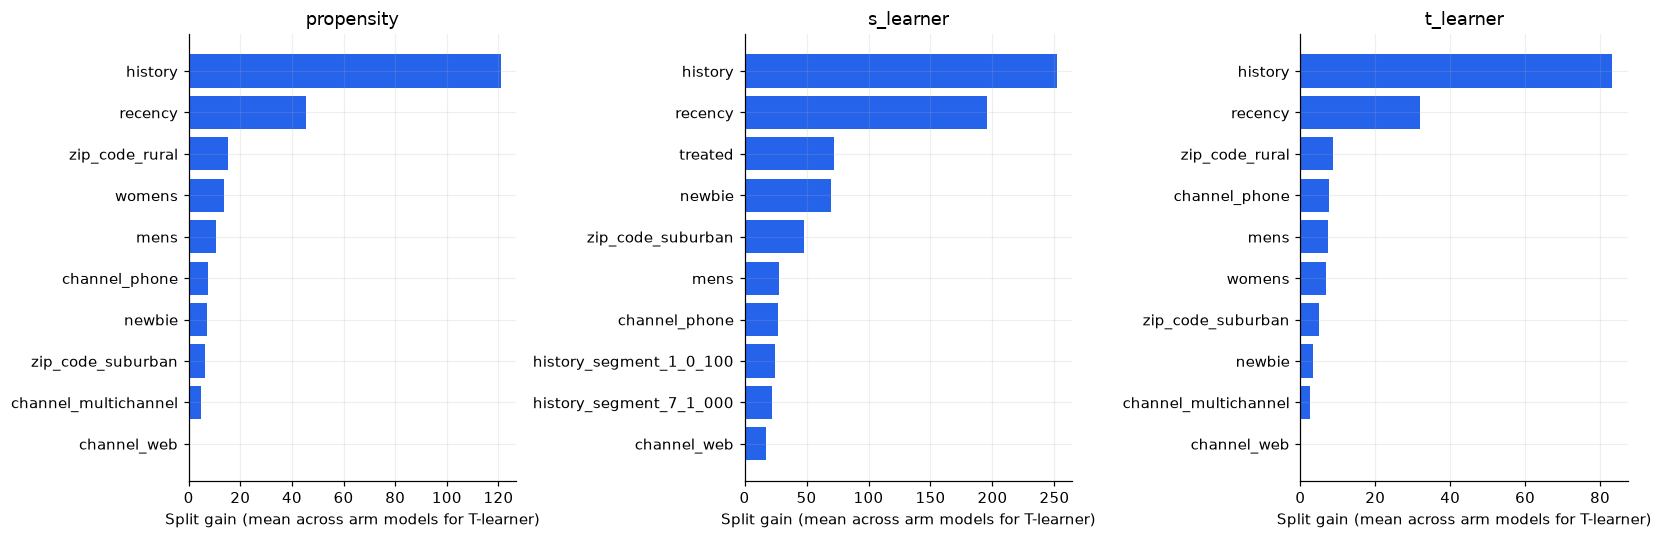

,learner,feature,gain
2,propensity,history,120.876149
7,propensity,recency,45.539460
16,propensity,zip_code_rural,15.379270
19,propensity,womens,13.595130
21,propensity,mens,10.519180
26,propensity,channel_phone,7.486100
28,propensity,newbie,6.963360
31,propensity,zip_code_suburban,6.411070
33,propensity,channel_multichannel,4.891240
37,propensity,channel_web,0.000000


In [29]:
model_entries = {name: {'model': model} for name, model in fitted_models.items()}
importance = feature_importance(model_entries, top=100)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for name, ax in zip(fitted_models, axes):
    top = importance[importance.learner == name].nlargest(10, 'gain').sort_values('gain')
    ax.barh(top.feature, top.gain, color='#2563eb')
    ax.set(xlabel='Split gain (mean across arm models for T-learner)', title=name)
plt.tight_layout()
plt.show()
display(importance.sort_values(['learner', 'gain'], ascending=[True, False]))

### Local MLflow tracking

If the optional tracking package is installed, record this rerun's parameters and numeric metrics in the configured **local SQLite** store. The code does not upload raw rows, customer scores or files. No hosted experiment service is needed. If tracking is absent, model fitting and evaluation above still run.

In [30]:
from campaign_ml.tracking import Tracker
tracker = Tracker.from_config(config)
for name, model in fitted_models.items():
    handle = tracker.start(f'notebook-{comparison["name"]}-{name}',
                           {'learner': name, 'comparison': comparison['name'], 'seed': seed,
                            'source_sha256': checksum, 'lightgbm': modelling['lightgbm']})
    numeric_metrics = {k: float(v) for k, v in model.metrics.items()
                       if isinstance(v, (int, float, np.number)) and np.isfinite(v)}
    numeric_metrics['holdout_qini_conversions'] = ev.qini_coefficient(conversion_curves[name])
    handle.log_metrics(numeric_metrics)
    handle.log_tags({'analysis_surface': 'executed_notebook', 'individual_effect_observable': 'no'})
    handle.finish()
print('Local MLflow runs recorded:', len(tracker.run_ids), '| tracking enabled:', tracker.enabled)

Local MLflow runs recorded: 3 | tracking enabled: True


## 7. Campaign economics: assumptions, not realized ROI

For a selected randomized slice, calculate
$$V_{scenario}=\widehat{\Delta S}\times n_{treated}\times assumed\ margin
-n_{treated}\times assumed\ cost\ per\ send.$$

Propagate the spend bootstrap interval through this fixed-margin calculation. The resulting bounds condition on the assumed cost and margin; they do not cover uncertainty in those assumptions. They also exclude long-term effects, execution costs, unsubscribe harm and delivery failure. A “positive scenario” is not measured profit.

,strategy,share_targeted,assumed_margin,assumed_cost_per_send,scenario_net_value,scenario_ci_low,scenario_ci_high
4,propensity,0.05,0.45,0.005,147.991905,-324.591009,718.505528
13,propensity,0.10,0.45,0.005,247.191405,-228.284211,833.511562
22,propensity,0.20,0.45,0.005,296.187236,-365.182957,1028.287121
31,propensity,0.30,0.45,0.005,769.649972,-67.500301,1630.836427
40,propensity,0.50,0.45,0.005,887.760207,-52.433940,1812.884030
49,propensity,0.75,0.45,0.005,999.815777,-66.231552,2067.940591
58,propensity,1.00,0.45,0.005,1490.421373,310.989884,2741.558107
67,s_learner,0.05,0.45,0.005,-57.366995,-272.875806,81.204356
76,s_learner,0.10,0.45,0.005,165.087568,-151.128217,574.165470
85,s_learner,0.20,0.45,0.005,355.799135,-59.077893,829.538419


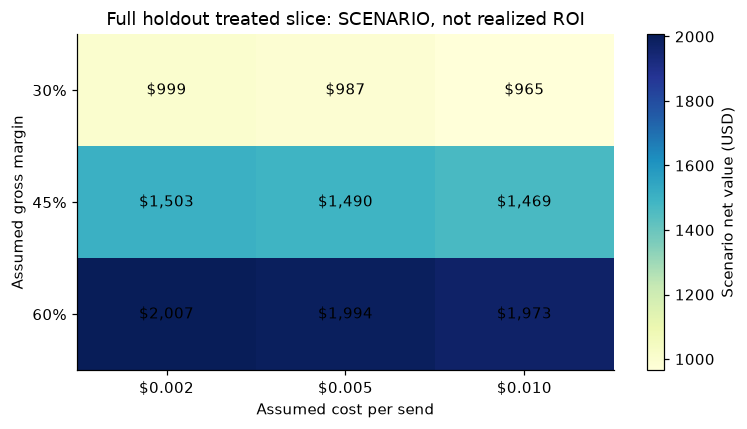

In [31]:
economics_rows = []
for row in policies.itertuples():
    for margin in config['economics']['margin_scenarios']:
        for cost in config['economics']['cost_scenarios']:
            send_cost = row.n_selected_treated * cost
            economics_rows.append({
                'strategy': row.strategy, 'share_targeted': row.share_targeted,
                'assumed_margin': margin, 'assumed_cost_per_send': cost,
                'scenario_net_value': row.incremental_spend_in_slice_usd*margin-send_cost,
                'scenario_ci_low': row.uplift_spend_ci_low*row.n_selected_treated*margin-send_cost,
                'scenario_ci_high': row.uplift_spend_ci_high*row.n_selected_treated*margin-send_cost,
            })
economics = pd.DataFrame(economics_rows)
base = economics[(economics.assumed_margin == config['economics']['gross_margin_rate'])
                 & (economics.assumed_cost_per_send == config['economics']['email_cost_per_send'])]
display(base)
full_grid = economics[(economics.strategy == 't_learner') & (economics.share_targeted == 1.0)]
grid = full_grid.pivot(index='assumed_margin', columns='assumed_cost_per_send', values='scenario_net_value')
fig, ax = plt.subplots(figsize=(7, 4))
image = ax.imshow(grid.to_numpy(), cmap='YlGnBu', aspect='auto')
ax.set(xticks=range(len(grid.columns)), xticklabels=[f'${v:.3f}' for v in grid.columns],
       yticks=range(len(grid.index)), yticklabels=[f'{100*v:.0f}%' for v in grid.index],
       xlabel='Assumed cost per send', ylabel='Assumed gross margin',
       title='Full holdout treated slice: SCENARIO, not realized ROI')
ax.grid(False)
for i in range(len(grid.index)):
    for j in range(len(grid.columns)):
        ax.text(j, i, f'${grid.iloc[i, j]:,.0f}', ha='center', va='center')
fig.colorbar(image, ax=ax, label='Scenario net value (USD)')
plt.tight_layout()
plt.show()

## 8. Decision summary and next experiment

The conclusions below are generated from the analysis in memory, not copied from a previous CSV. The ranking and policy comparisons are exploratory holdout readouts: absence of a demonstrated advantage is not proof that every future targeting model will fail.

In [32]:
lines = ['### Results from this execution']
for row in headline.itertuples():
    scale, unit = (1, 'USD/customer') if row.outcome == 'spend' else (100, 'pp')
    lines.append(f'- **{row.comparison}, {row.outcome}:** {scale*row.effect:+.3f} {unit}; '
                 f'family-wise CI [{scale*row.ci_low_fwer:+.3f}, {scale*row.ci_high_fwer:+.3f}]; '
                 f'Holm p={row.p_holm:.3g}.')
for row in survivors.itertuples():
    lines.append(f'- **Exploratory interaction:** {row.comparison} x {row.subgroup_variable}, '
                 f'Holm p={row.p_holm:.4f}; requires prospective confirmation.')
for row in ranking_metrics.itertuples():
    lines.append(f'- **{row.learner}:** conversion Qini area above diagonal '
                 f'{row.qini_coefficient_conversions:+.3f}.')
lines.append(f'- **T-learner vs propensity at 5%:** {first_budget.incremental_conversions_difference:+.2f} '
             f'conversions [{first_budget.difference_ci_low:+.2f}, {first_budget.difference_ci_high:+.2f}].')
display(Markdown(chr(10).join(lines)))

### Results from this execution
- **mens_vs_control, conversion:** +0.681 pp; family-wise CI [+0.474, +0.887]; Holm p=3.05e-13.
- **mens_vs_control, visit:** +7.659 pp; family-wise CI [+6.900, +8.418]; Holm p=1.14e-111.
- **mens_vs_control, spend:** +0.770 USD/customer; family-wise CI [+0.443, +1.093]; Holm p=0.0004.
- **womens_vs_control, conversion:** +0.311 pp; family-wise CI [+0.127, +0.495]; Holm p=0.000157.
- **womens_vs_control, visit:** +4.523 pp; family-wise CI [+3.798, +5.248]; Holm p=3.18e-44.
- **womens_vs_control, spend:** +0.424 USD/customer; family-wise CI [+0.135, +0.720]; Holm p=0.001.
- **Exploratory interaction:** womens_vs_control x newbie, Holm p=0.0152; requires prospective confirmation.
- **propensity:** conversion Qini area above diagonal -0.639.
- **s_learner:** conversion Qini area above diagonal -0.060.
- **t_learner:** conversion Qini area above diagonal -0.750.
- **T-learner vs propensity at 5%:** -0.73 conversions [-3.66, +0.73].

### Recommendations and boundaries

1. **Both emails show positive average conversion and spending increments versus no email.** Mens has the larger point estimate. This notebook's confirmatory families compare each campaign with control; choosing between the campaigns should consider their content, audience and deployment economics rather than confuse two separate p-values with a direct comparison test.
2. **Do not deploy uplift targeting on the strength of this holdout.** Primary conversion Qini is negative and the paired fixed-budget readout does not establish an advantage over the response baseline. A measured average campaign lift is not evidence that the model knows which individual is persuadable.
3. **Investigate the Womens-by-newbie pattern prospectively.** It is the surviving adjusted interaction, but subgroup risk differences are exploratory and data from the same historical experiment are not independent confirmation.
4. **Collect more pre-campaign behavioral features and more conversion events, then test a frozen policy in a new randomized campaign.** Compare uplift, response and random/full-list policies at a budget chosen before reading results. Preserve a no-contact control and report conversion, spend, costs and adverse outcomes.
5. **Keep business economics explicitly conditional.** No measured margin, campaign cost or long-term outcome exists here. The scenario grid cannot be described as realized ROI.

### Reproducibility checks completed here
- Raw checksum and quality gates pass.
- Training, validation and test IDs are disjoint.
- Numeric preprocessing statistics agree with training rows only.
- Model matrices contain no blocked outcomes or assignment-derived features.
- Each decile contains both randomized arms.
- Paired differences equal the two standalone list estimates under shared tie breaking.
- Full-list policies have identical conversion effects.

Run `python -m pytest` separately for the repository's unit/integration suite. This notebook does not claim a live BigQuery load, a Tableau publication, or fresh external validation.